In [1]:
import time
import csv
import struct
import json
from tqdm import tqdm

exp_name = 'Oct30'

OUTPUT_JSONL = '../data/' + exp_name + '/1_Quasi_Static_Log.jsonl'

In [2]:
import json
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error

# === Load data ===
data = []
with open(OUTPUT_JSONL, 'r') as f:
    for line in f:
        data.append(json.loads(line))
print(f"Loaded {len(data)} records.")

# === Extract features: Orientation angles ===
X = np.array([[entry["robot_data"]['X_Pos'][3], entry["robot_data"]['X_Pos'][4], entry["robot_data"]['X_Pos'][5]] for entry in data])  # rx, ry, rz

# === Target: full FF_EE vector (force + torque) ===
y = np.array([entry['robot_data']['FF_EE'][:6] for entry in data])  # FF_EE[0:6]

# === Train/test split ===
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# === Create pipeline ===
degree = 3
model = Pipeline([
    ('poly', PolynomialFeatures(degree)),
    ('regressor', MultiOutputRegressor(LinearRegression()))
])
model.fit(X_train, y_train)

# === Evaluate ===
y_pred = model.predict(X_test)
total_mse = mean_squared_error(y_test, y_pred)
print(f"Total MSE (FF_EE[0:6]): {total_mse:.6f}")

for i in range(6):
    mse_i = mean_squared_error(y_test[:, i], y_pred[:, i])
    print(f"FF_EE[{i}] MSE: {mse_i:.6f}")


Loaded 441 records.
Total MSE (FF_EE[0:6]): 0.000021
FF_EE[0] MSE: 0.000026
FF_EE[1] MSE: 0.000080
FF_EE[2] MSE: 0.000017
FF_EE[3] MSE: 0.000000
FF_EE[4] MSE: 0.000000
FF_EE[5] MSE: 0.000000


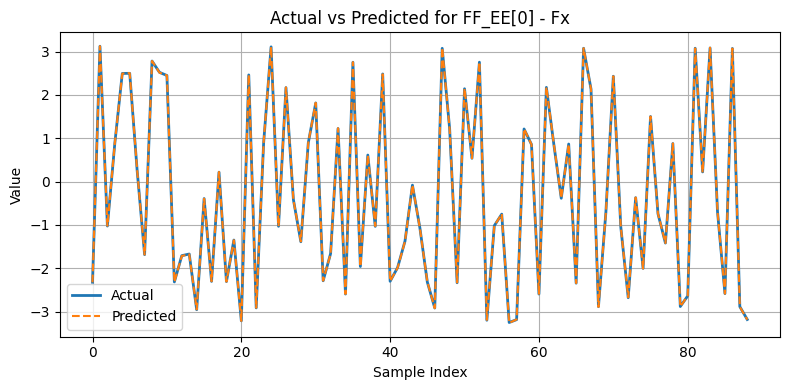

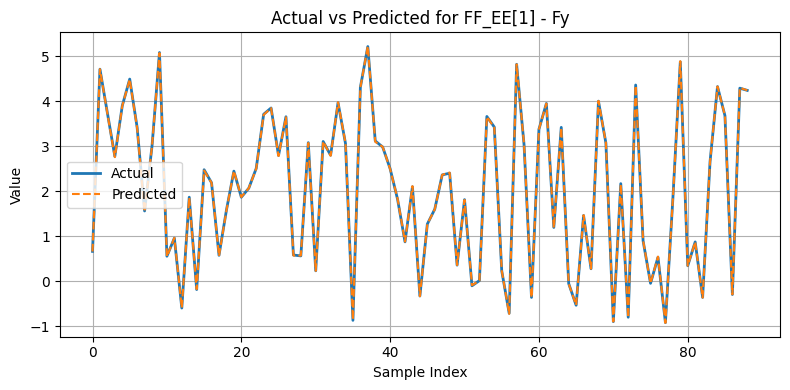

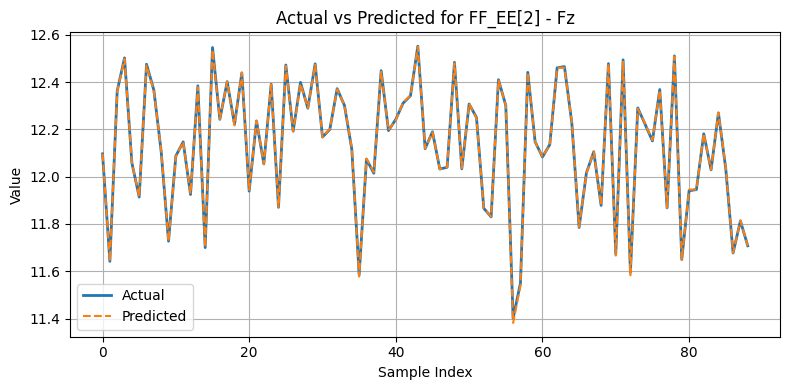

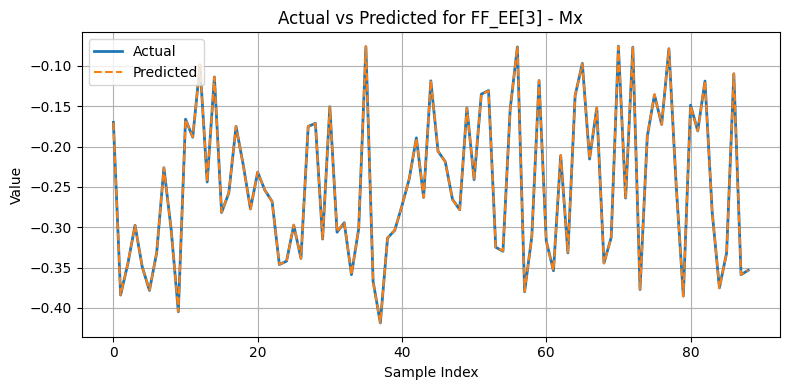

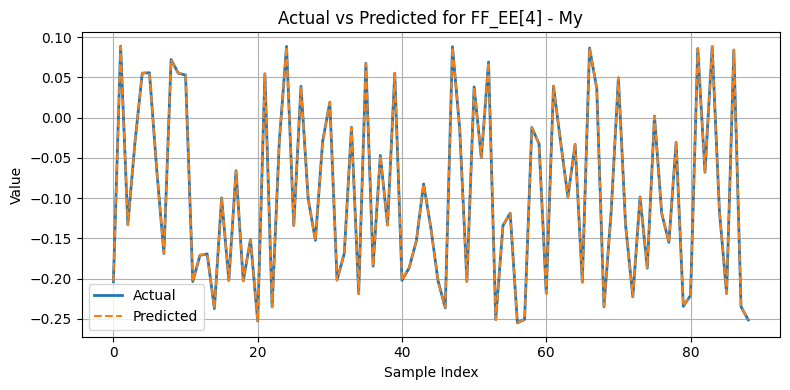

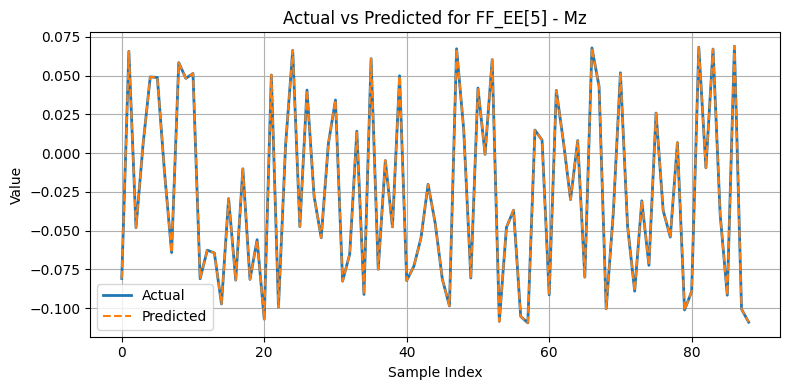

In [3]:
import matplotlib.pyplot as plt

# Number of points to plot
N = 100
subset_indices = np.arange(min(N, len(X_test)))

# Updated labels for all 6 components
component_labels = [
    'FF_EE[0] - Fx',
    'FF_EE[1] - Fy',
    'FF_EE[2] - Fz',
    'FF_EE[3] - Mx',
    'FF_EE[4] - My',
    'FF_EE[5] - Mz'
]

# Plot all components
for i in range(6):
    plt.figure(figsize=(8, 4))
    plt.plot(subset_indices, y_test[subset_indices, i], label='Actual', linewidth=2)
    plt.plot(subset_indices, y_pred[subset_indices, i], label='Predicted', linestyle='--')
    plt.title(f'Actual vs Predicted for {component_labels[i]}')
    plt.xlabel('Sample Index')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [4]:
import os
import joblib
# === Save model ===
os.makedirs('../models/' + exp_name, exist_ok=True)
joblib.dump(model, '../models/' + exp_name + '/1_Quasi_Static_Poly.pkl')
print("Model saved to ../models/" + exp_name + "/1_Quasi_Static_Poly.pkl")

Model saved to ../models/Oct30/1_Quasi_Static_Poly.pkl
